# Evaluation and error analysis

In the latest notebook, we fine-tuned five transformer models and took a look at some preliminary results, i.e. metrics like precision, recall, and f1 score.

However, these numbers do not reveal the real pain points of classification errors for Finnish:
- Which classes are performing well? Why?
- Are texts with multiple inflected forms performing worse?
- Do we see a pattern among the incorrectly classified samples?

Let's look at what kind of data the models struggle with and compare results!

##Load predictions

Let's get the predictions we generated in notebook 2, which are in a .csv with the following columns: **text**, **true_label**, **predicted_label**.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
from pathlib import Path

drive_path = Path('/content/drive/MyDrive/NLP/results/evaluation')

print(f"Target path exists: {drive_path.exists()}")

Target path exists: True


In [ ]:
import pandas as pd

predictions_dict = {}

csv_paths = list(drive_path.glob("*/*/predictions.csv"))
print(f"Found {len(csv_paths)} predictions.csv files:\n")

for path in csv_paths:
    research_group = path.parts[-3]
    model_name = path.parts[-2]
    try:
        df = pd.read_csv(path)
        predictions_dict[(research_group, model_name)] = df
        print(f"Loaded: Group='{research_group}', Model='{model_name}' -> Rows, columns: {df.shape}")
    except Exception as e:
        print(f"Error loading {path}: {e}")

In [ ]:
if predictions_dict:
    first_model_df = list(predictions_dict.values())[0]
    top_10_classes = sorted(first_model_df['true_label'].unique().tolist())
    print("Number of classes:", len(top_10_classes))
else:
    print("Warning: No prediction files were loaded. Please make sure Google Drive is mounted.")

The mappings for our classes are as follows:

```- "calendar_query": 0
- "calendar_set": 1
- "datetime_query": 2
- "email_query": 3
- "email_sendemail": 4
- "general_quirky": 5
- "news_query": 6
- "play_music": 7
- "qa_factoid": 8
- "weather_query": 9

## Overall performance
A reminder of the metrics-based evaluation we got in notebook 2 to complement this analysis.

In [5]:
import pandas as pd

comparison_csv_path = drive_path / "model_comparison.csv"

if comparison_csv_path.exists():
    metrics_df = pd.read_csv(comparison_csv_path)
    print("Successfully loaded model comparison metrics:")
    display(metrics_df)
else:
    print(f"Could not find model comparison file at: {comparison_csv_path}")

Successfully loaded model comparison metrics:


,research_group,model,accuracy,precision,recall,macro_f1,loss,runtime,samples_per_second,steps_per_second
0,TurkuNLP,bert-base-finnish-cased-v1,0.907173,0.912724,0.909578,0.910706,0.320169,2.3143,614.452,76.915
1,Finnish-NLP,roberta-large-finnish-v2,0.905063,0.908060,0.910896,0.908442,0.366391,5.4477,261.028,32.674
2,TurkuNLP,finnish-modernbert-base,0.893812,0.898369,0.898945,0.898023,0.382733,10.1663,139.873,17.509
3,FacebookAI,xlm-roberta-base,0.893812,0.901608,0.895063,0.896702,0.376840,2.3866,595.831,74.584
4,dmis-lab,UltraBERT-150M,0.860759,0.861998,0.866311,0.863174,0.641621,12.9032,110.206,13.795


## Confusion matrix — which intents are confusing?

We will create confusion matrices to understand which labels the model is struggling with and which ones are performing the best. This way we can see which intents are confused by the model.

In [6]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion_matrix_for_model(model_name, ax=None):
    """
    Plots the confusion matrix for a specific model loaded in predictions_dict.
    Arguments:
        model_name (str): Name of the model to plot (e.g. 'finnish-modernbert-base')
        ax (matplotlib.axes.Axes, optional): Pre-existing axes to plot onto.
    """
    matched_key = None
    for key in predictions_dict.keys():
        if key[1] == model_name:
            matched_key = key
            break

    if matched_key is None:
        print(f"Model '{model_name}' not found in loaded predictions. Available models are:")
        for key in predictions_dict.keys():
            print(f"  - {key[1]}")
        return

    group, name = matched_key
    df = predictions_dict[matched_key]

    labels_order = list(top_10_classes)
    y_true = df['true_label']
    y_pred = df['predicted_label']

    if y_true.dtype in [np.int64, np.int32, int]:
        y_true_mapped = [top_10_classes[i] for i in y_true]
        y_pred_mapped = [top_10_classes[i] for i in y_pred]
    else:
        y_true_mapped = y_true
        y_pred_mapped = y_pred

    cm = confusion_matrix(y_true_mapped, y_pred_mapped, labels=labels_order)

    local_plot = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))
        local_plot = True

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_order)
    disp.plot(ax=ax, xticks_rotation=45, cmap='Blues', values_format='d')

    if local_plot:
        ax.set_title(f"Confusion Matrix: {name}", fontsize=14, weight='bold')
        plt.tight_layout()
        plt.show()
    else:
        ax.set_title(f"{group} / {name}", fontsize=12, weight='bold')

def plot_all_confusion_matrices():
    """
    Plots confusion matrices for all loaded models in a grid.
    """
    if not predictions_dict:
        print("No predictions found in predictions_dict. Please load them first.")
        return

    num_models = len(predictions_dict)
    ncols = 2
    nrows = (num_models + 1) // 2

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6 * ncols, 5 * nrows))

    if nrows == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for idx, (group, name) in enumerate(predictions_dict.keys()):
        plot_confusion_matrix_for_model(model_name=name, ax=axes[idx])

    for ax in axes[num_models:]:
        fig.delaxes(ax)

    plt.suptitle("Confusion Matrices Comparison\n", fontsize=16, weight='bold', y=1.02)
    plt.tight_layout()
    fig.subplots_adjust(hspace=0.4)
    plt.show()

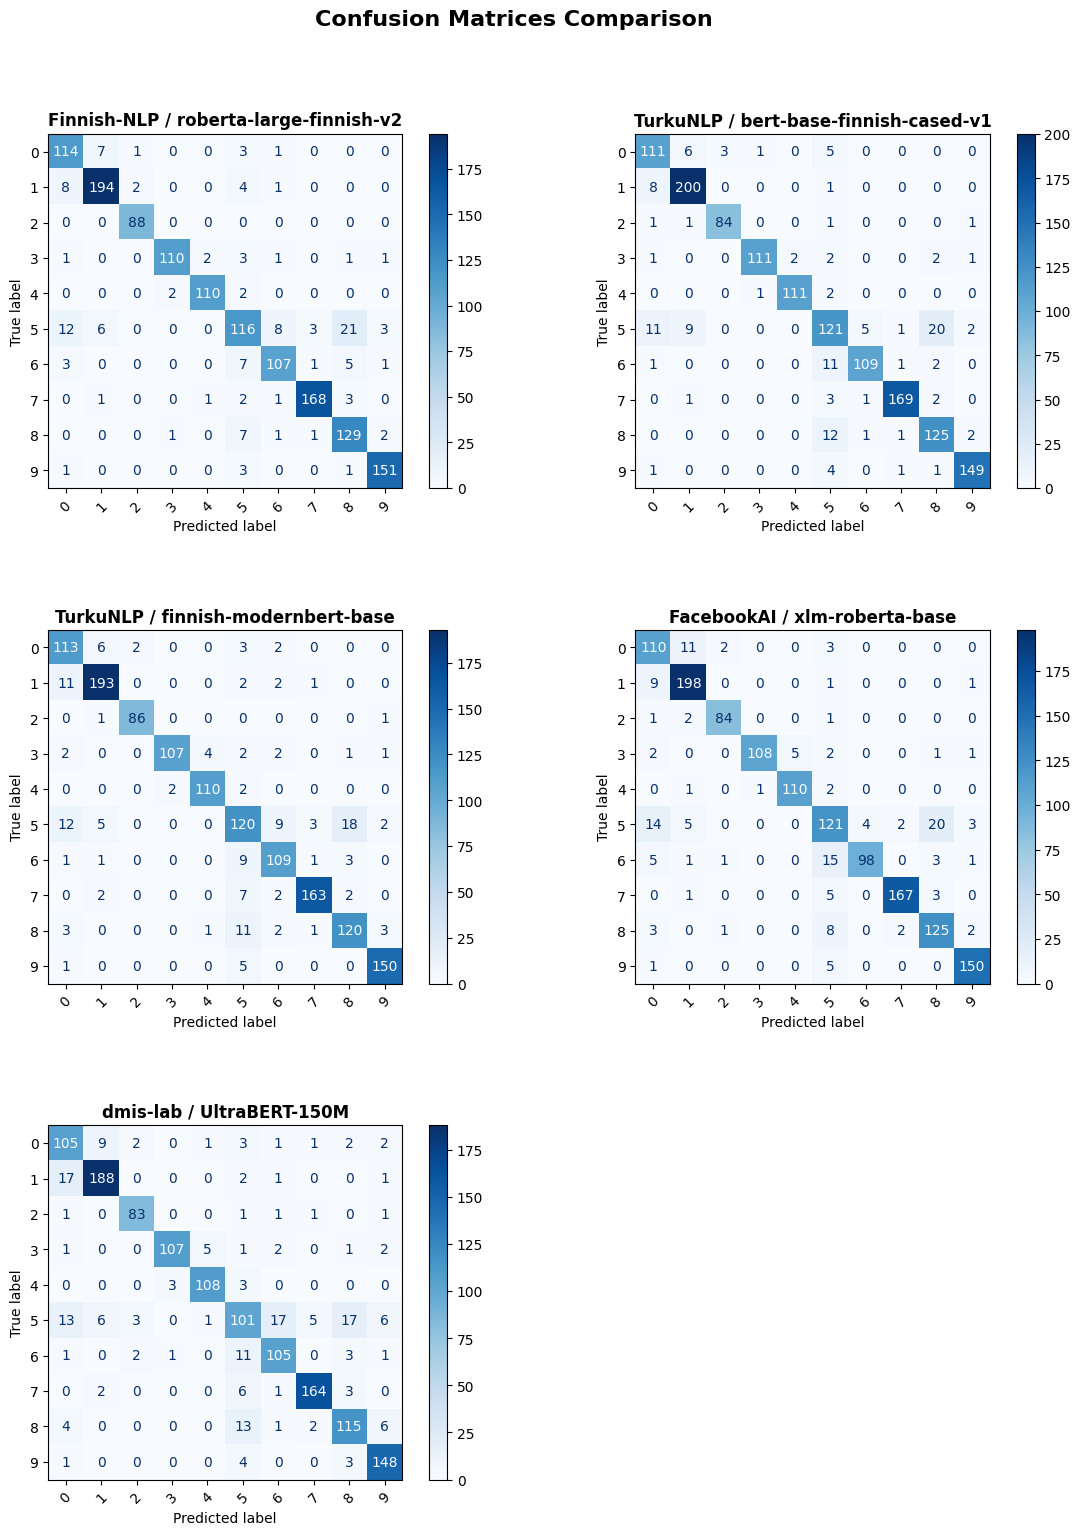

In [7]:
plot_all_confusion_matrices()

We observe that the all models seem to make mistakes more or less on the same classes.

Some mistakes include:
- predicting label 5 as 8
- predicting label 5 as 0
- predicting label 6 as 5
- predicting label 5 as 6
- predicting label 0 as 1
- predicting label 8 as 5
- predicting label 3 as 4

This means that the greatest classification errors stem from confusing:
- `general_quirky` with `qa_factoid`
- `news_query` with `general_quirky`
- `general_quirky` with `calendar_query`.

> **Solution?** The training samples in these classes should be reviewed to improve the model.



## Misclassified samples — what and why?

Let's look at some misclassified samples to understand what kind of utterances are confusing and why the model might be confusing them.

In [8]:
import pandas as pd

pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)

def analyze_and_align_errors():
    if not predictions_dict:
        print("No predictions found. Please load the prediction files first.")
        return None

    # Start with text and true labels from the first model
    first_key = list(predictions_dict.keys())[0]
    base_df = predictions_dict[first_key][['text', 'true_label']].copy()

    # Map label indices to their names if they are integers
    label_mapping = {
        0: "calendar_query",
        1: "calendar_set",
        2: "datetime_query",
        3: "email_query",
        4: "email_sendemail",
        5: "general_quirky",
        6: "news_query",
        7: "play_music",
        8: "qa_factoid",
        9: "weather_query"
    }

    if base_df['true_label'].dtype in [int, 'int64', 'int32']:
        base_df['true_label'] = base_df['true_label'].map(label_mapping)

    # Add prediction columns for each model
    error_cols = []
    for (_, model_name), df in predictions_dict.items():
        pred_col = f"prediction_{model_name}"
        # Ensure we align by index or directly map since they have the exact same length and order
        preds = df['predicted_label']
        if preds.dtype in [int, 'int64', 'int32']:
            preds = preds.map(label_mapping)
        base_df[pred_col] = preds

        # Create a boolean helper column to track if this model made an error
        is_error_col = f"error_{model_name}"
        base_df[is_error_col] = base_df['true_label'] != base_df[pred_col]
        error_cols.append(is_error_col)

    # Count how many models made a mistake on each sample
    base_df['total_error_count'] = base_df[error_cols].sum(axis=1)

    # Filter to only keep rows where at least one model made an error
    error_df = base_df[base_df['total_error_count'] > 0].copy()

    # Sort by the number of models that failed (descending) to show the most frequent/difficult errors first
    error_df = error_df.sort_values(by='total_error_count', ascending=False)

    # Drop the temporary boolean helper columns for the final display
    cols_to_keep = ['text', 'true_label'] + [col for col in error_df.columns if col.startswith('prediction_')] + ['total_error_count']
    final_error_table = error_df[cols_to_keep]

    return final_error_table

In [26]:
error_table = analyze_and_align_errors()
if error_table is not None:
    print(f"Found {len(error_table)} samples where at least one model made a prediction error.")
    display(error_table.head(5))

Found 295 samples where at least one model made a prediction error.


,text,true_label,prediction_roberta-large-finnish-v2,prediction_bert-base-finnish-cased-v1,prediction_finnish-modernbert-base,prediction_xlm-roberta-base,prediction_UltraBERT-150M,total_error_count
1396,etsi anni,email_query,qa_factoid,qa_factoid,qa_factoid,qa_factoid,qa_factoid,5
1205,kuinka voimme saada luottoa,email_sendemail,general_quirky,general_quirky,general_quirky,general_quirky,general_quirky,5
1204,kuinka se on tullut meihin,email_sendemail,general_quirky,general_quirky,general_quirky,general_quirky,general_quirky,5
1202,aihe,email_query,general_quirky,general_quirky,general_quirky,general_quirky,news_query,5
1161,verrattuna ihmisiin,qa_factoid,general_quirky,general_quirky,general_quirky,general_quirky,general_quirky,5


### Analysis of individual samples

Many of the incorrectly classified samples fall into one of the following categories. Let's take a look at them and some possible solution for improving the results.

- **Ambiguity:** Lack of explicit context in the text or short texts.

  *   "aihe"
  *   "etsi anni"
  *   "hei rakas"
  > **Solution?** Add context (e.g. surrounding messages or app information) to support classification. If not available, using a confidence threshold to flag ambiguous samples for manual review is another option.

- **Two similar correct classes:** The sample's true label and predicted label are both technically correct.

  *   "miksi maapallo on pyöreä" is annotated as `general quirky` but `qa_factoid` is not wrong either
  *   "kuinka voimme saada luottoa" is annotated as `email_sendemail`, while `general_quirky` or `qa_factoid` is not wrong either
  > **Solution?** Refine class definitions and expand dataset with samples that differentiate classes, especially borderline cases. Consider allowing multi-label classification if applicable for the task.

- **Niche vocabulary**: It seems like samples with application and product names are not well processed, especially since they lack context.

  *   "tarkista outlook"
  *   "pandora"
  > **Solution?** Use data augmentation to expand the dataset with longer samples that include niche vocabulary, so they are in context. However, include short and context-free examples as well, since these are real-world inputs.

- **Implicit intent**: Although all samples include relevant words, some lack the explicit action:

  *   "varttia vaille kaksi" could be any intent related to date or calendar, even a song name
  *   "seitsemän vuoden välein" seems like a fragment of a longer utterance

  > **Solution?** Use data augmentation to expand the dataset with explicit actions that are in line with the annotation.

- **Incorrect annotations?** These type of errors boil down to data annotation quality. In the following samples, all five models have predicted a class I would have assigned as well:

  *   "millaiset ilmasto olosuhteet sillä alueella" has the true label `qa_factoid`, while all models classify it as `weather_query`
  *   "baseball tulokset" has the true label `general_quirky`, while all models classify it as `news_query`
  * "näytä tapaamiset" has the true label `calendar set`, while all models classify it as `calendar_query`
  > **Solution?** Review annotation guidelines and product goals. Re-evaluate samples if multiple models consistently predict a different class, and correct labels in the dataset if needed.

In addition to these errors, common mistakes may be related to **linguistic variation** (i.e. accents and dialects) and **emerging vocabulary** (e.g. "brainrot", "selfie"...) that the models haven't seen.

## Analysis across models

Let's determine whether there are any patterns that affect all five models or if it is a pattern concentrated in particular models.

### 1. Overlapping errors

In [10]:
if 'error_table' in globals() and error_table is not None:
    # 1. Calculate overall metrics of shared failures
    errors_all_five = len(error_table[error_table['total_error_count'] == 5])
    total_errors = len(error_table)
    percentage_of_errors = (errors_all_five / total_errors) * 100

    print(f"Number of samples where all 5 models made an error: {errors_all_five} out of {total_errors} misclassified samples ({percentage_of_errors:.2f}%)\n")

    # 2. Extract and display the class breakdown of those shared errors
    hard_samples = error_table[error_table['total_error_count'] == 5]
    class_counts = hard_samples['true_label'].value_counts()

    print("=== True Classes of the 67 Shared Errors ===")
    for label, count in class_counts.items():
        print(f"- {label}: {count} samples")
else:
    print("error_table is not available. Please run the cell containing analyze_and_align_errors() first.")

Number of samples where all 5 models made an error: 67 out of 295 misclassified samples (22.71%)

=== True Classes of the 67 Shared Errors ===
- general_quirky: 24 samples
- email_query: 8 samples
- news_query: 8 samples
- calendar_set: 6 samples
- qa_factoid: 5 samples
- calendar_query: 5 samples
- weather_query: 5 samples
- play_music: 4 samples
- email_sendemail: 2 samples


Interestingly, out of the 295 classification errors, **all five models often struggle on the same samples** - more specifically, on 67 samples, which account for 22.71% of all errors. The main issue is in `general_quirky`.

> The training data for `general_quirky` should be reviewed and expanded.

### 2. Model Disagreement Analysis
Let's isolate samples where the models disagreed, meaning at least one model predicted the correct intent while others failed. This helps us see which models have unique strengths or handled specific linguistic phenomena better.

In [29]:
if 'error_table' in globals() and error_table is not None:
    # Disagreement where 2 or 3 models failed
    disagreement_df = error_table[(error_table['total_error_count'] >= 2) & (error_table['total_error_count'] <= 3)].copy()

    print(f"Found {len(disagreement_df)} samples where exactly 2 or 3 models failed.\n")

    # Sort by text length to find longer, more syntactically rich utterances
    disagreement_df['text_len'] = disagreement_df['text'].apply(lambda x: len(str(x)))
    interesting_examples = disagreement_df.sort_values(by=['text_len', 'true_label'], ascending=[False, True])

    print("=== Surfacing Interesting & Complex Disagreement Examples (Sorted by length / complexity) ===")
    display(interesting_examples[['text', 'true_label', 'total_error_count'] + [col for col in interesting_examples.columns if col.startswith('prediction_')]].head(5))
else:
    print("error_table is not available.")

Found 88 samples where exactly 2 or 3 models failed.

=== Surfacing Interesting & Complex Disagreement Examples (Sorted by length / complexity) ===


,text,true_label,total_error_count,prediction_roberta-large-finnish-v2,prediction_bert-base-finnish-cased-v1,prediction_finnish-modernbert-base,prediction_xlm-roberta-base,prediction_UltraBERT-150M
1016,haluan sen muistavan valintani ja suosittelevan minulle asioita niihin perustuen kun pyydän,general_quirky,2,general_quirky,calendar_set,general_quirky,general_quirky,calendar_set
1258,vastaatko sarille että olen kiireinen projektien kanssa seuraavat kolme viikkoa,email_sendemail,2,email_sendemail,email_sendemail,email_sendemail,calendar_set,general_quirky
987,voitko luoda sokerittoman ruokavalion minulle ja luoda ostoslistan ainesosille,general_quirky,2,general_quirky,calendar_set,general_quirky,general_quirky,play_music
670,minun täytyy vahvistaa kaikki tämän päivän tapaamiset voiko henkilön kutsua,calendar_query,2,calendar_query,calendar_query,calendar_query,calendar_set,calendar_set
80,mitkä ovat b. b. c. kyselyn ennusteet tulevista yhdysvaltain vaaleista,news_query,2,weather_query,news_query,news_query,news_query,general_quirky


There are some interesting differences between the models:

- "kuuma aihe" is classified correctly by **FinBERT** and **Finnish RoBERTa** as `news_query` - but not so much so by the other models
- "helli korviani behmillä" is correctly classified as `play_music` by only **FinBERT** and **Finnish RoBERTa.**
- "minulla on jazz fiilis juuri nyt mites sinulla" is correctly classified as `play_music` by Finnish **RoBERTa** and **UltraBERT**
- "mitkä ovat b. b. c. kyselyn ennusteet tulevista yhdysvaltain vaaleista" is correctly classified as `news_query` by **FinBERT**, **ModernBERT**, and **XLM-Roberta**. Finnish RoBERTa and UltraBERT fail to understand it is about news.
-  "sain juuri villeltä sähköpostia johon minun täytyy vastata juuri nyt" is correctly classified as an email-related intent by all models, but only **UltraBERT** and **Finnish RoBERTa** understand that it is `email_sendemail`

According to these comparisons, **Finnish RoBERTa** and **FinBERT** seem to be doing a pretty good job!

### 3. Error rate per class
Let's look at where the errors are more prominent and whether some models perform better on some classes. We already know that `general_quirky` is a tricky category.

=== Error Percentages (%) of Total Samples in Each Class per Model ===


Model,UltraBERT-150M,bert-base-finnish-cased-v1,finnish-modernbert-base,roberta-large-finnish-v2,xlm-roberta-base,Class_Total_Samples
Class,,,,,,
calendar_query,16.67,11.90,10.32,9.52,12.70,126
calendar_set,10.05,4.31,7.66,7.18,5.26,209
datetime_query,5.68,4.55,2.27,0.00,4.55,88
email_query,10.08,6.72,10.08,7.56,9.24,119
email_sendemail,5.26,2.63,3.51,3.51,3.51,114
general_quirky,40.24,28.40,28.99,31.36,28.40,169
news_query,15.32,12.10,12.10,13.71,20.97,124
play_music,6.82,3.98,7.39,4.55,5.11,176
qa_factoid,18.44,11.35,14.89,8.51,11.35,141


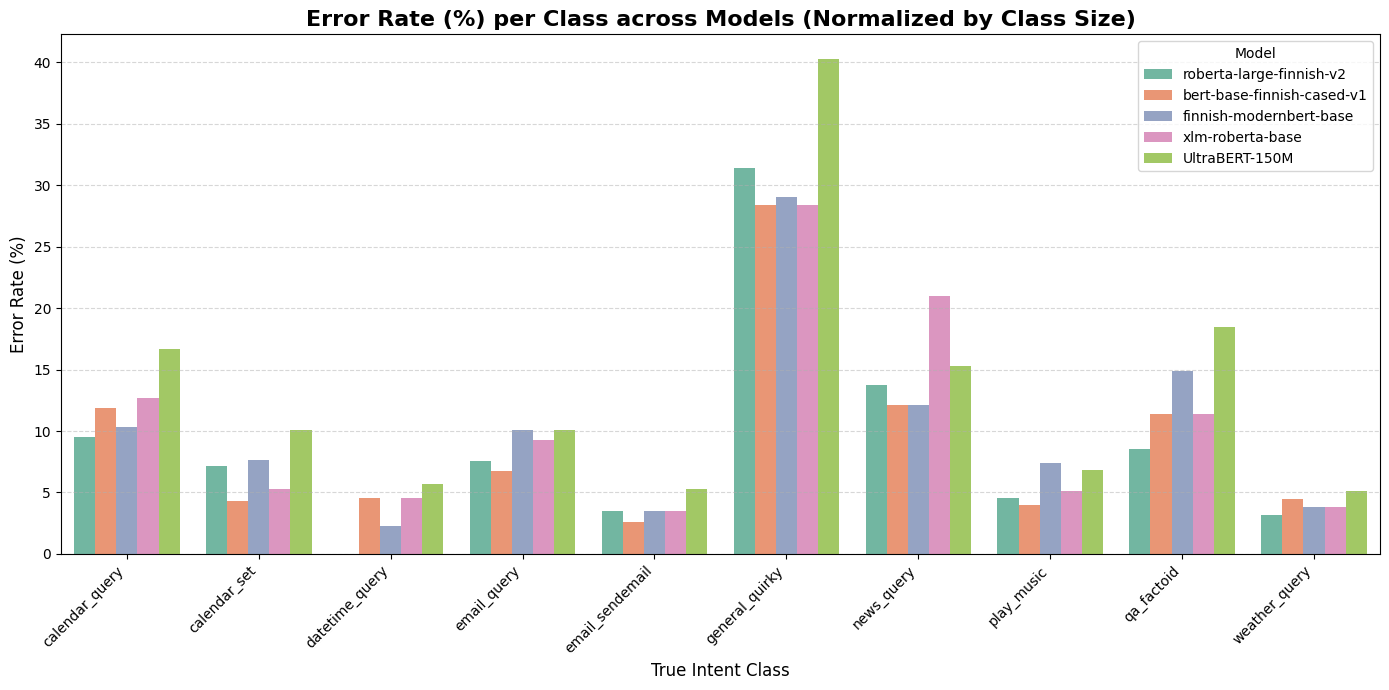

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def calculate_and_plot_misclassifications_per_class():
    if 'predictions_dict' not in globals() or not predictions_dict:
        print("No predictions found in predictions_dict. Please load them first.")
        return

    # Class mapping from indices to names
    label_mapping = {
        0: "calendar_query",
        1: "calendar_set",
        2: "datetime_query",
        3: "email_query",
        4: "email_sendemail",
        5: "general_quirky",
        6: "news_query",
        7: "play_music",
        8: "qa_factoid",
        9: "weather_query"
    }

    # Find total samples per class in the evaluation set
    first_key = list(predictions_dict.keys())[0]
    first_df = predictions_dict[first_key].copy()
    if first_df['true_label'].dtype in [int, 'int64', 'int32']:
        first_df['true_label'] = first_df['true_label'].map(label_mapping)

    class_totals = first_df['true_label'].value_counts().to_dict()

    records = []

    # Calculate error count per true label for each model
    for (_, model_name), df in predictions_dict.items():
        df_copy = df.copy()

        # Standardize labels to strings
        if df_copy['true_label'].dtype in [int, 'int64', 'int32']:
            df_copy['true_label'] = df_copy['true_label'].map(label_mapping)
            df_copy['predicted_label'] = df_copy['predicted_label'].map(label_mapping)

        # Identify errors
        errors_df = df_copy[df_copy['true_label'] != df_copy['predicted_label']]

        # Count misclassified samples per true class
        error_counts = errors_df['true_label'].value_counts()

        # Record counts and percentages for every class
        for class_name in label_mapping.values():
            total = class_totals.get(class_name, 1)  # avoid division by zero
            errors = error_counts.get(class_name, 0)
            records.append({
                'Model': model_name,
                'Class': class_name,
                'Misclassifications': errors,
                'Error Rate (%)': round((errors / total) * 100, 2),
                'Total Samples': total
            })

    # Create a DataFrame
    error_summary_df = pd.DataFrame(records)

    # Pivot the DataFrame for error percentages
    pivot_pct = error_summary_df.pivot(index='Class', columns='Model', values='Error Rate (%)').fillna(0.0)

    # Append a Total Samples column helper for reference
    pivot_pct['Class_Total_Samples'] = pivot_pct.index.map(class_totals)

    print("=== Error Percentages (%) of Total Samples in Each Class per Model ===")
    display(pivot_pct)

    # Visualize the percentages instead of raw counts
    plt.figure(figsize=(14, 7))
    sns.barplot(
        data=error_summary_df,
        x='Class',
        y='Error Rate (%)',
        hue='Model',
        palette='Set2'
    )
    plt.title('Error Rate (%) per Class across Models (Normalized by Class Size)', fontsize=16, weight='bold')
    plt.xlabel('True Intent Class', fontsize=12)
    plt.ylabel('Error Rate (%)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

calculate_and_plot_misclassifications_per_class()

We observe that:
- `general_quirky` is the most universally challenging intent with error rates spanning from 28 to 40%
- `news_query` performs a lot worse on `xlm-roberta-base`
- `UltraBERT` is  consistently making the most mistakes - which makes sense, since it is not a model pretrained on Finnish data.
- `datetime_query`, `email_sendemail` and `weather_query` are highly accurate across all models

### 4. Utterance Length
Let's analyze if there's a correlation between utterance length (word count) and if models struggle with it.



=== Normalized Error Rates (%) by Length Bucket ===


Model,UltraBERT-150M,bert-base-finnish-cased-v1,finnish-modernbert-base,roberta-large-finnish-v2,xlm-roberta-base
Length Bucket,,,,,
Short (1-3 words),18.37,12.59,16.67,11.90,12.24
Medium (4-6 words),11.71,7.77,8.60,8.24,8.84
Long (7+ words),15.81,10.31,10.31,10.65,14.09


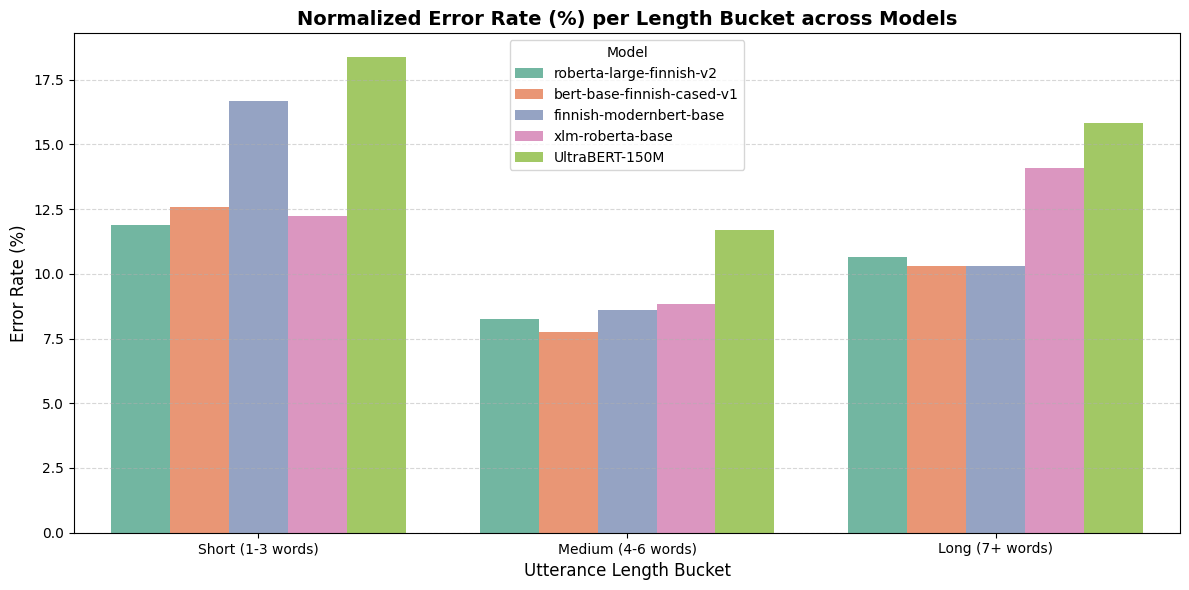

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_error_rates_by_length():
    if 'predictions_dict' not in globals() or not predictions_dict:
        print("No predictions found. Please load prediction files first.")
        return

    # Get true labels and texts from the first model to construct the base dataset
    first_key = list(predictions_dict.keys())[0]
    base_df = predictions_dict[first_key][['text', 'true_label']].copy()

    # Compute word counts for all test inputs
    base_df['word_count'] = base_df['text'].apply(lambda x: len(str(x).split()))

    # Define length buckets
    def get_bucket(count):
        if count <= 3:
            return 'Short (1-3 words)'
        elif count <= 6:
            return 'Medium (4-6 words)'
        else:
            return 'Long (7+ words)'

    base_df['length_bucket'] = base_df['word_count'].apply(get_bucket)

    # Total samples per bucket in our evaluation set
    bucket_totals = base_df['length_bucket'].value_counts().to_dict()

    records = []
    for (_, model_name), df in predictions_dict.items():
        df_copy = df.copy()
        df_copy['word_count'] = df_copy['text'].apply(lambda x: len(str(x).split()))
        df_copy['length_bucket'] = df_copy['word_count'].apply(get_bucket)

        # Count errors in each bucket
        errors_df = df_copy[df_copy['true_label'] != df_copy['predicted_label']]
        error_counts = errors_df['length_bucket'].value_counts().to_dict()

        for bucket in ['Short (1-3 words)', 'Medium (4-6 words)', 'Long (7+ words)']:
            total = bucket_totals.get(bucket, 0)
            errors = error_counts.get(bucket, 0)
            rate = (errors / total) * 100 if total > 0 else 0.0
            records.append({
                'Model': model_name,
                'Length Bucket': bucket,
                'Total Samples': total,
                'Errors': errors,
                'Error Rate (%)': round(rate, 2)
            })

    summary_df = pd.DataFrame(records)

    # Display the summary table
    pivot_table = summary_df.pivot(index='Length Bucket', columns='Model', values='Error Rate (%)')
    pivot_table = pivot_table.reindex(['Short (1-3 words)', 'Medium (4-6 words)', 'Long (7+ words)'])

    print("=== Normalized Error Rates (%) by Length Bucket ===")
    display(pivot_table)

    # Plotting
    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=summary_df,
        x='Length Bucket',
        y='Error Rate (%)',
        hue='Model',
        order=['Short (1-3 words)', 'Medium (4-6 words)', 'Long (7+ words)'],
        palette='Set2'
    )
    plt.title('Normalized Error Rate (%) per Length Bucket across Models', fontsize=14, weight='bold')
    plt.xlabel('Utterance Length Bucket', fontsize=12)
    plt.ylabel('Error Rate (%)', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

analyze_error_rates_by_length()

We observe that:
- Not only short texts are misclassified - medium and long texts perform only a little better.
- The sweet spot is "Medium" - every single model achieves its lowest error rate in this range (ranging from 7.77% to 11.71%).

We can conclude that this is happening because shorter texts lack context, whereas longer texts probably introduce some noise.


Let's take a look at some random samples of correctly classified utterances and misclassified utterances that have the same length.

In [17]:
def show_real_world_length_examples():
    if 'predictions_dict' not in globals() or not predictions_dict:
        print("No predictions found. Please load prediction files first.")
        return

    # Use the first model (e.g., Finnish RoBERTa) to pull qualitative examples
    model_key = [k for k in predictions_dict.keys() if 'roberta-large' in k[1]][0]
    df = predictions_dict[model_key].copy()

    # Class mapping
    label_mapping = {
        0: "calendar_query", 1: "calendar_set", 2: "datetime_query",
        3: "email_query", 4: "email_sendemail", 5: "general_quirky",
        6: "news_query", 7: "play_music", 8: "qa_factoid", 9: "weather_query"
    }

    df['true_label'] = df['true_label'].map(label_mapping)
    df['predicted_label'] = df['predicted_label'].map(label_mapping)
    df['word_count'] = df['text'].apply(lambda x: len(str(x).split()))
    df['is_correct'] = df['true_label'] == df['predicted_label']

    print("=========================================================================")
    print("  QUALITATIVE EXAMPLES: SHORT UTTERANCES (1-3 words)")
    print("=========================================================================")

    print("\n🟢 CORRECTLY CLASSIFIED:")
    display(df[(df['word_count'] <= 3) & df['is_correct']][['text', 'true_label']].head(4))

    print("\n🔴 MISCLASSIFIED:")
    display(df[(df['word_count'] <= 3) & ~df['is_correct']][['text', 'true_label', 'predicted_label']].head(4))

    print("\n=========================================================================")
    print("  QUALITATIVE EXAMPLES: LONG UTTERANCES (7+ words)")
    print("=========================================================================")

    print("\n🟢 CORRECTLY CLASSIFIED:")
    display(df[(df['word_count'] >= 7) & df['is_correct']][['text', 'true_label']].head(4))

    print("\n🔴 MISCLASSIFIED:")
    display(df[(df['word_count'] >= 7) & ~df['is_correct']][['text', 'true_label', 'predicted_label']].head(4))

show_real_world_length_examples()

  QUALITATIVE EXAMPLES: SHORT UTTERANCES (1-3 words)

🟢 CORRECTLY CLASSIFIED:


,text,true_label
7,mikä päivämäärä on,datetime_query
11,soita rock soittolistani,play_music
13,mitä kello on,datetime_query
23,millainen sää on,weather_query



🔴 MISCLASSIFIED:


,text,true_label,predicted_label
26,seitsemän vuoden välein,play_music,calendar_set
52,get marksilta,weather_query,qa_factoid
91,käyttäjäystävällinen,news_query,general_quirky
107,pandora,play_music,qa_factoid



  QUALITATIVE EXAMPLES: LONG UTTERANCES (7+ words)

🟢 CORRECTLY CLASSIFIED:


,text,true_label
12,laita päälle minun soittolista ja soita kolmas laulu jonossa,play_music
17,minulla on jazz fiilis juuri nyt mites sinulla,play_music
25,kerro minulle sää barcelonassa kahden päivän päästä,weather_query
53,soita se kappale jonka laulaa katri helena,play_music



🔴 MISCLASSIFIED:


,text,true_label,predicted_label
20,mikä on vaihtokurssi yhdysvaltojen dollarista englannin puntaan,news_query,qa_factoid
80,mitkä ovat b. b. c. kyselyn ennusteet tulevista yhdysvaltain vaaleista,news_query,weather_query
254,kuinka monta tornadoa tässä kuussa on ollut,general_quirky,qa_factoid
255,olly kuinka monta tornadoa on ollut tässä kuussa,general_quirky,qa_factoid


For short texts, we observe that the classification mistakes stem from ambiguity. The short texts that were correctly classified include keywords like "kello", "rock", "sää", whereas the misclassified utterances are fragments without any context.

For long texts, we can can conclude similar behaviour for correctly classified samples - they include explicit keywords that are relevant for the class ("kappale", "sää", "jazz", "laulu"). For misclassified examples, the classes are more not closely connected to the class. we are dealing with the more complicated `qa_factoid` and `general_quirky` classes, which get mixed up.

### 5. Finnish-Specific Linguistic Analysis
Finnish is morphologically rich. Let's evaluate whether grammatical complexity (heavy case inflection and long compound words) makes our models struggle more.

In [23]:
# Ensure spaCy's Finnish pipeline is downloaded and installed
try:
    import spacy
    try:
        nlp = spacy.load("fi_core_news_sm")
    except OSError:
        print("Downloading spaCy Finnish model...")
        subprocess.run([sys.executable, "-m", "spacy", "download", "fi_core_news_sm"], check=True)
        nlp = spacy.load("fi_core_news_sm")
except ImportError:
    print("Installing spaCy...")
    subprocess.run([sys.executable, "-m", "pip", "install", "spacy"], check=True)
    import spacy
    subprocess.run([sys.executable, "-m", "spacy", "download", "fi_core_news_sm"], check=True)
    nlp = spacy.load("fi_core_news_sm")

In [31]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import subprocess
import sys

def analyze_model_vulnerability_to_finnish_linguistics_table():
    if 'predictions_dict' not in globals() or not predictions_dict:
        print("No predictions found in predictions_dict. Please load them first.")
        return None

    # Use the first model to build our base linguistic indicators
    first_key = list(predictions_dict.keys())[0]
    base_df = predictions_dict[first_key][['text', 'true_label']].copy()

    # 1. Indicator for Compound Words (longer individual words)
    base_df['max_word_len'] = base_df['text'].apply(lambda x: max([len(w) for w in str(x).split()]) if len(str(x).split()) > 0 else 0)
    base_df['has_long_compound'] = base_df['max_word_len'] > 10

    # 2. Indicator for Suffix/Inflectional Richness using spaCy's Morphological Parser
    def count_spacy_inflections(text):
        doc = nlp(str(text))
        count = 0
        for token in doc:
            # Get morphology dictionary
            morph = token.morph.to_dict()
            # If word is a nominal (Noun, Adj, Pronoun, Numeral) and has a Case feature that is NOT Nominative
            if token.pos_ in ['NOUN', 'ADJ', 'PRON', 'NUM', 'PROPN']:
                case = morph.get('Case')
                # Nominative (Nom) is the base uninflected form. Non-nominative cases are inflected.
                if case and case != 'Nom':
                    count += 1
        return count

    print("Running spaCy Finnish morphological parsing over the evaluation set (this may take a few seconds)...")
    base_df['inflection_count'] = base_df['text'].apply(count_spacy_inflections)
    # Classify as "Highly Inflected" if there are 2 or more grammatical case inflections
    base_df['is_highly_inflected'] = base_df['inflection_count'] >= 2

    # Map labels to names to ensure string matching matches earlier standardization
    label_mapping = {
        0: "calendar_query", 1: "calendar_set", 2: "datetime_query",
        3: "email_query", 4: "email_sendemail", 5: "general_quirky",
        6: "news_query", 7: "play_music", 8: "qa_factoid", 9: "weather_query"
    }
    if base_df['true_label'].dtype in [int, 'int64', 'int32']:
        base_df['true_label'] = base_df['true_label'].map(label_mapping)

    records = []

    for (_, model_name), df in predictions_dict.items():
        df_copy = df.copy()
        if df_copy['true_label'].dtype in [int, 'int64', 'int32']:
            df_copy['true_label'] = df_copy['true_label'].map(label_mapping)
            df_copy['predicted_label'] = df_copy['predicted_label'].map(label_mapping)

        df_copy['is_error'] = df_copy['true_label'] != df_copy['predicted_label']

        # Align indicators
        df_copy['has_long_compound'] = base_df['has_long_compound']
        df_copy['is_highly_inflected'] = base_df['is_highly_inflected']

        # Calculate error rates for Compound Indicator
        for cond in [True, False]:
            sub_df = df_copy[df_copy['has_long_compound'] == cond]
            total_cond = len(sub_df)
            errors_cond = sub_df['is_error'].sum()
            err_rate = (errors_cond / total_cond) * 100 if total_cond > 0 else 0.0
            records.append({
                'Model': model_name,
                'Condition': 'Text has Long Words (>10 chars)' if cond else 'Text has standard Word Lengths',
                'Feature': 'Compound Word Vulnerability',
                'Error Rate (%)': err_rate,
                'Total Samples': total_cond
            })

        # Calculate error rates for Inflection Indicator
        for cond in [True, False]:
            sub_df = df_copy[df_copy['is_highly_inflected'] == cond]
            total_cond = len(sub_df)
            errors_cond = sub_df['is_error'].sum()
            err_rate = (errors_cond / total_cond) * 100 if total_cond > 0 else 0.0
            records.append({
                'Model': model_name,
                'Condition': 'Highly Inflected (>=2 cases)' if cond else 'Low Inflections (<2 cases)',
                'Feature': 'Case Inflection Vulnerability',
                'Error Rate (%)': err_rate,
                'Total Samples': total_cond
            })

    summary_df = pd.DataFrame(records)

    # Display tables
    print("=== Percentage of misclassified samples within category ===")
    pivot_df = summary_df.pivot(index='Condition', columns='Model', values='Error Rate (%)')
    display(pivot_df.round(2))

    return summary_df

def plot_model_vulnerability_to_finnish_linguistics_graphs(summary_df):
    if summary_df is None or summary_df.empty:
        print("No data provided to plot.")
        return

    # Visualizations
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    comp_data = summary_df[summary_df['Feature'] == 'Compound Word Vulnerability']
    sns.barplot(ax=axes[0], data=comp_data, x='Condition', y='Error Rate (%)', hue='Model', palette='Set2')
    axes[0].set_title('Error Rate by Word Length (Compound Indicator)', fontsize=12, weight='bold')
    axes[0].set_ylabel('Error Rate (%)')
    axes[0].grid(axis='y', linestyle='--', alpha=0.5)

    infl_data = summary_df[summary_df['Feature'] == 'Case Inflection Vulnerability']
    sns.barplot(ax=axes[1], data=infl_data, x='Condition', y='Error Rate (%)', hue='Model', palette='Set2')
    axes[1].set_title('Error Rate by spaCy Inflectional Suffix Density', fontsize=12, weight='bold')
    axes[1].set_ylabel('Error Rate (%)')
    axes[1].grid(axis='y', linestyle='--', alpha=0.5)

    plt.suptitle('Percentage of misclassified samples within category (via spaCy)', fontsize=15, weight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [35]:
summary_df = analyze_model_vulnerability_to_finnish_linguistics_table()

Running spaCy Finnish morphological parsing over the evaluation set (this may take a few seconds)...
=== Percentage of misclassified samples within category ===


Model,UltraBERT-150M,bert-base-finnish-cased-v1,finnish-modernbert-base,roberta-large-finnish-v2,xlm-roberta-base
Condition,,,,,
Highly Inflected (>=2 cases),13.63,10.16,10.53,10.04,12.02
Low Inflections (<2 cases),14.31,8.13,10.73,8.78,8.78
Text has Long Words (>10 chars),10.45,6.51,8.14,7.60,8.55
Text has standard Word Lengths,17.66,12.26,13.28,11.53,12.85


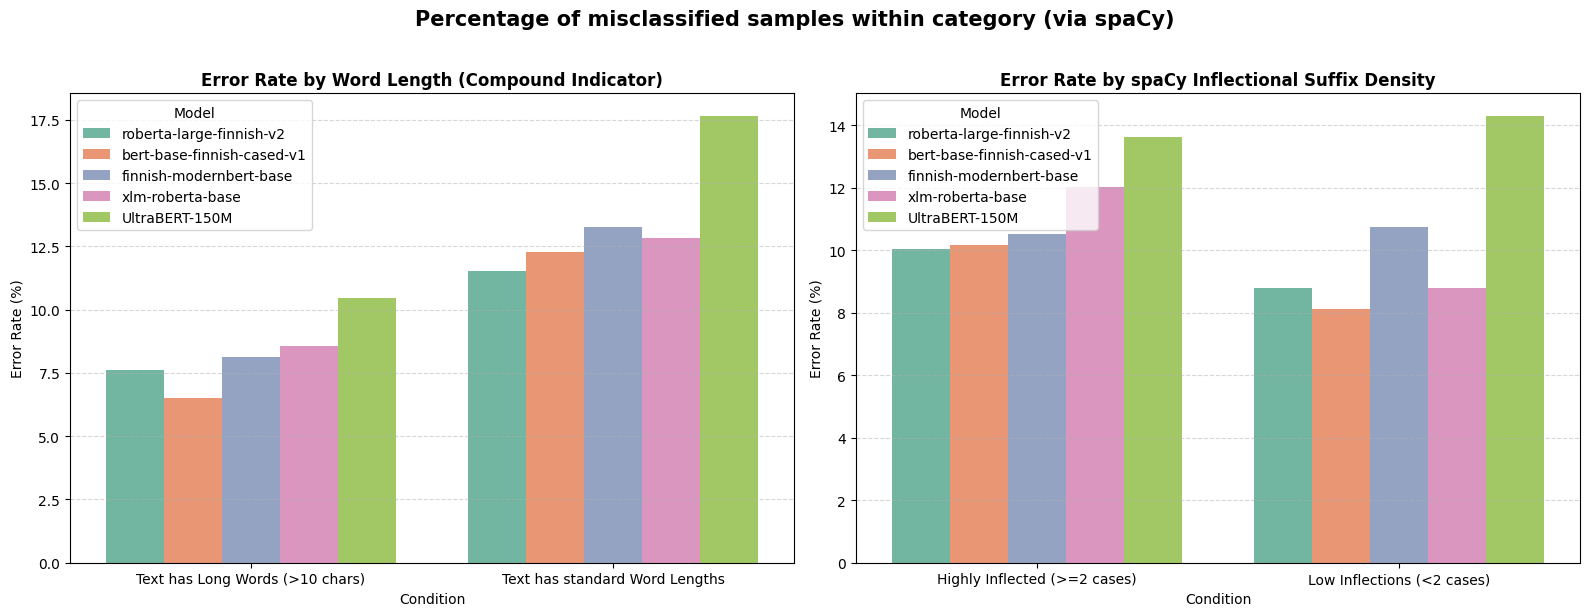

In [36]:
plot_model_vulnerability_to_finnish_linguistics_graphs(summary_df)

We observe that regarding long words and inflected forms, Finnish RoBERTa and FinBERT seem to have the lowest error rates.

Surprisingly, a longer word length does not give worse classification results. The texts with long words have, in fact, a lower error rate than the texts with standard word lengths. This may be due to good quality data and and the fact that tokenization splits sentences anyway.

## Conclusion

Through this multi-model error analysis, we have uncovered how different transformer architectures handle the structural and semantic complexities of the Finnish language:

### 1. Model Standouts
- **FinBERT (`bert-base-finnish-cased-v1`)** and **Finnish RoBERTa (`roberta-large-finnish-v2`)** are the undisputed top performers, achieving exceptional classification accuracy ($≈ 90.7\%$ and $≈ 90.5\%$ respectively) and showing a massive **93.81% exact prediction agreement** (1,334 out of 1,422 matching predictions).
- This native pretraining advantage is heavily underscored when contrasted with multilingual architectures like **XLM-RoBERTa-base**, which is more vulnerable to morphological complexity, demonstrating a **36.9% relative increase in error rate** when handling highly inflected Finnish nouns and adjectives (jumping from 8.78% to 12.02% error rate).
- Surprisingly, newer models like **Finnish ModernBERT** fell slightly short of these long-standing baselines, indicating that mature Finnish-pretrained models remain highly robust options for structured intent classification.

### 2. Linguistic Sweet Spots vs. Noise
- **Utterance Length Dynamics:** Our length evaluation debunked the assumption that longer context inherently benefits classifiers. Instead, we demonstrated a clear **U-shaped curve** where "Medium" (4-6 words) is the optimal sweet spot for all models (achieving the lowest error rates between 7.77% and 11.71%) for an intent classification task.
- **The Compound Word Paradox:** While highly inflected case structures increase error rates due to morphological ambiguity, long words ($>10$ characters) consistently correlated with lower error rates (e.g., only 6.51% for FinBERT). This suggests compound words act as strong, unambiguous semantic anchors for specific intent classes.

### 3. Next Steps for Dataset Quality
Changing model architectures alone will not fix the final performance gaps. To reach production readiness, we must address the root data issues:
- **Clean the `general_quirky` Class:** This remains the single largest universal bottleneck, with error rates of over 40% due to overlapping annotations with `qa_factoid` and `news_query`.
- **Resolve Borderline Annotations:** Address verified misannotations that came up in our error logs (e.g. "*näytä tapaamiset*" mapped to `calendar set` instead of `calendar_query` which all models correctly clustered).
- **Augment Ambiguous Inputs:** Introduce explicit action cues to short, contextless queries to reduce ambiguity.

## Extra note - Production readiness

Even if a model has a great F1 score and the manual revision looks good, the evaluation covered in this notebook is merely academic and decisions should not be made based on them. Besides testing on our data, it is also good practice to comapre the results to benchmarks, such as SQuAD or GLUE.

For production, we need additional evaluation metrics to ensure smooth user experience and a stable environment. It should be an on-going task to make sure the system does not degrade. These include measuring:
- Latency
- Memory requirements
- Monetary cost
- Edge cases (long inputs, new classes, unclear classes, new vocabulary...)

Also, a product should be prepared with fallback behaviour when the class is not clear, i.e. when the predicted label's confidence score does not meet a certain threshold. In cases like "pandora", if the confidence score is low, the system could confirm is the user wants to open the Pandora app.